# FDEM1D — verification and benchmark notebook

Tests and benchmarks **FDEM1D** (Hanssens et al., 2019, *IEEE GRSM* 7(1), 74–85) against two independent
1D layered-earth codes, for the **current** repository version and a **refactored** version.

| Reference | Physics | Frame | Used for |
|---|---|---|---|
| **empymod** | full-wave (σ, μ = μ0(1+κ), ε), adaptive quadrature (`ht='qwe'`) | z positive **down** | forward ppm, all orientations |
| **SimPEG** `Simulation1DLayered` | quasi-static (σ, real μ; no ε) | z positive **up** | forward ppm, analytic Jacobians (σ, κ) |
| analytic / invariants | free-space dipole, LIN asymptote, reciprocity, layer splitting | — | references that need no external code |

**Sections**
1. Configuration · 2. Setup · 3. Conventions and shared problem description · 4. Reference engines
5. FDEM1D adapters · 6. Test cases · 7. Forward benchmarks · 8. Invariant tests · 9. Sensitivity tests
10. Performance · 11. Current vs refactored · 12. Summary

**How to use:** set `REF_PATH` / `NEW_PATH` in the next cell. If `NEW_PATH` does not exist, all NEW columns are
skipped. If the refactored version changes the public API, edit `RefactoredFDEM1DAdapter` (section 5) — every
test only talks to the adapter, never to the FDEM1D API directly.

## 1. Configuration

In [1]:
from pathlib import Path

REF_PATH = Path("FDEM1D.py")              # current repo version (github.com/SENSE-UGent/FDEM1D, commit 7fe39e3)
NEW_PATH = Path("FDEM1D_refactored.py")   # refactored version; NEW is skipped if this file is missing
NEW_ADAPTER = "legacy"                    # "legacy": NEW keeps the Sensor/Model/Calculate API; "refactored": edit section 5

RUN_SIMPEG = True       # SimPEG forward + Jacobian references
RUN_TIMING = True       # performance section
FAST = False            # reduced test grid for quick checks
SAVE_RESULTS = False    # write CSV tables next to this notebook

# Tolerances (scaled error = |FDEM1D − ref| / max_f |ref| over the frequency sweep; see section 7 for justification)
RTOL_EMPYMOD = 1e-3
RTOL_SIMPEG = 1e-3
RTOL_VERSION = 1e-6     # REF vs NEW: identical numerics expected outside documented fixes
RTOL_SENS_FD = 2e-2     # FDEM1D sensitivity (1 % one-sided step) vs independent central difference
RTOL_SENS_SIMPEG = 2e-2 # FDEM1D sensitivity vs SimPEG analytic Jacobian

# The current repo version returns shape-(1,) arrays from forward(), which makes sensitivity() crash on NumPy >= 2.
# The shim wraps forward() to return scalars (REF only) so that the *other* sensitivity defects stay observable.
# The raw crash is still reported by the "forward returns scalars" input-contract test (section 8).
SHIM_REF_SCALAR_RETURN = True

## 2. Setup

In [2]:
import copy
import importlib.util
import platform
import time
import warnings
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.constants import epsilon_0, mu_0

import empymod

try:
    import simpeg
    import simpeg.electromagnetics.frequency_domain as sp_fdem
    from simpeg import maps as sp_maps
    HAVE_SIMPEG = True
except ImportError:
    HAVE_SIMPEG = False
RUN_SIMPEG = RUN_SIMPEG and HAVE_SIMPEG

warnings.filterwarnings("ignore", category=RuntimeWarning)   # legacy FDEM1D emits divide-by-zero warnings
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)

print(f"python {platform.python_version()} | numpy {np.__version__} | scipy {scipy.__version__} | "
      f"empymod {empymod.__version__} | simpeg {simpeg.__version__ if HAVE_SIMPEG else 'not installed'}")


def load_module(path, name):
    """Import a FDEM1D version from a file path under a unique module name (None if missing)."""
    path = Path(path)
    if not path.is_file():
        return None
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


ref_module = load_module(REF_PATH, "fdem1d_ref")
new_module = load_module(NEW_PATH, "fdem1d_new")
assert ref_module is not None, f"REF_PATH not found: {REF_PATH.resolve()}"
print("REF:", REF_PATH.resolve())
print("NEW:", NEW_PATH.resolve() if new_module else f"{NEW_PATH} not found -> NEW columns skipped")

python 3.12.3 | numpy 2.4.4 | scipy 1.17.1 | empymod 2.6.0 | simpeg 0.0.0+zip
REF: /tmp/nbexec/FDEM1D.py
NEW: FDEM1D_refactored.py not found -> NEW columns skipped


## 3. Conventions and shared problem description

All results are expressed in **one convention**, that of Hanssens et al. (2019) Fig. 1 and empymod:

- **Frame:** z positive **down**, ground surface at z = 0. Tx at (0, 0, −h_Tx), Rx at (x, y, −h_Rx), heights > 0 in air.
- **Orientation `'AB'`:** A = transmitter dipole direction, B = receiver component (Fig. 2 of the paper).
  "Z" points **down** in this frame.
- **Time dependence:** e^{+iωt} (FDEM1D, empymod and SimPEG agree; QP > 0 over conductive ground for HCP).
- **Normalisation (eq. 15):** ppm = 10⁶ · H^S / H⁰, with H⁰ the free-space field *in the Tx direction* at the Rx
  (H_Z⁰ for Z sources, H_X⁰ / H_Y⁰ for X / Y sources) — FDEM1D's rule, applied identically to every reference.
- **SimPEG → z-down:** each "Z" in the orientation flips sign (Tx moment and/or Rx component), so
  H_zdown = (−1)^(number of Z) · H_SimPEG.

The problem is described once (`Geometry`, `LayeredEarth`) and translated into each code's input by small
functions — this is the only place where code-specific conventions live.

In [3]:
@dataclass(frozen=True)
class Geometry:
    """Loop-loop geometry. Heights are elevations above the ground surface (m, > 0 in air)."""
    name: str
    offset_m: float                 # horizontal Tx–Rx separation rho (m)
    tx_height_m: float              # Tx elevation h_Tx (m)
    azimuth_deg: float = 0.0        # Rx azimuth from +x (deg)
    rx_height_m: float | None = None  # Rx elevation (m); None -> same as Tx

    @property
    def rx_height(self):
        return self.tx_height_m if self.rx_height_m is None else self.rx_height_m

    @property
    def rx_xy_m(self):
        azimuth_rad = np.deg2rad(self.azimuth_deg)
        return self.offset_m * np.cos(azimuth_rad), self.offset_m * np.sin(azimuth_rad)


@dataclass(frozen=True)
class LayeredEarth:
    """Horizontally layered earth, top -> down. The basement (last layer) has no thickness."""
    name: str
    thickness_m: tuple              # n_layers - 1 finite thicknesses (m)
    conductivity_s_per_m: tuple     # n_layers (S/m)
    susceptibility_si: tuple        # n_layers, real (in-phase) volume susceptibility (-)
    rel_permittivity: tuple         # n_layers, eps / eps_0 (-)

    def __post_init__(self):
        n_layers = len(self.conductivity_s_per_m)
        if not (len(self.susceptibility_si) == len(self.rel_permittivity) == n_layers
                and len(self.thickness_m) == n_layers - 1):
            raise ValueError(f"{self.name}: inconsistent layer counts")

    @property
    def n_layers(self):
        return len(self.conductivity_s_per_m)

    def with_property(self, par, values):
        field = {"con": "conductivity_s_per_m", "sus": "susceptibility_si"}[par]
        return LayeredEarth(**{**self.__dict__, field: tuple(float(v) for v in values)})


UNIT_VECTOR_ZDOWN = {"X": np.array([1.0, 0, 0]), "Y": np.array([0, 1.0, 0]), "Z": np.array([0, 0, 1.0])}


def free_space_normaliser(geometry, tx_direction, moment_am2=1.0):
    """Static free-space dipole field (A/m) in the Tx direction at the Rx: M (3 (a.R^)^2 - 1) / (4 pi R^3).

    Quasi-static near field; the full-wave correction is O((k0 R)^2) < 1e-5 for R < 100 m, f <= 1e5 Hz.
    Uses the full 3D Tx->Rx vector (correct also when Tx and Rx heights differ).
    """
    x_m, y_m = geometry.rx_xy_m
    tx_to_rx_zdown_m = np.array([x_m, y_m, geometry.tx_height_m - geometry.rx_height])  # z_rx - z_tx
    distance_m = np.linalg.norm(tx_to_rx_zdown_m)
    cos_angle = UNIT_VECTOR_ZDOWN[tx_direction] @ tx_to_rx_zdown_m / distance_m
    return moment_am2 * (3.0 * cos_angle**2 - 1.0) / (4.0 * np.pi * distance_m**3)


def zup_to_zdown_sign(orientation):
    """Sign mapping a z-up result (SimPEG) onto the z-down frame: one flip per 'Z' in the orientation."""
    return (-1.0) ** orientation.count("Z")


def scalar(value):
    """Collapse legacy shape-(1,) outputs to a Python scalar (complex-safe)."""
    return np.ravel(value)[0].item()

## 4. Reference engines

- **empymod:** secondary field from `xdirect=None` (reflected field only, Tx and Rx both in air),
  normalised by empymod's own free-space field for the Tx direction, so empymod's source-strength scaling
  cancels. `ht='qwe'` (adaptive quadrature, tightened settings) is used because the default digital filter deviated by
  ~0.6 % at 100 kHz, and default QWE settings by 5.5e-3 at 40 m offset, in preliminary checks.
- **empymod quasi-static variant** (`quasi_static=True`: ε = 0 in air and ground) — used only in the
  diagnostic of section 7 to separate full-wave effects from implementation errors.
- **SimPEG:** secondary field (A/m, M = 1 A·m²) from `PointMagneticFieldSecondary(data_type='field')`; its
  built-in ppm is *not* used (it normalises by the primary projected on the Rx axis, which is 0 for PRP).
  Converted to z-down and normalised with `free_space_normaliser`. Quasi-static → compared against FDEM1D runs
  with ground permittivity set to 0.

In [4]:
EMPYMOD_COMPONENT = {"X": 4, "Y": 5, "Z": 6}   # empymod: 4/5/6 = magnetic x/y/z; ab = <receiver><source>
AIR_RESISTIVITY_OHM_M = 2e14
# Tightened QWE settings: the defaults left a 5.5e-3 reference error at 40 m offset / 100 kHz (checked against
# rtol=1e-12, nquad=101); with these settings the reference converges to < 1e-6 for all cases in section 6.
EMPYMOD_HTARG = {"rtol": 1e-12, "atol": 1e-30, "nquad": 101, "maxint": 200}


def empymod_ppm(geometry, earth, frequencies_hz, orientation, quasi_static=False):
    """Full-wave (default) or quasi-static reference ppm (z-down frame, eq. 15 normalisation)."""
    tx, rx = orientation
    x_m, y_m = geometry.rx_xy_m
    common = dict(src=[0.0, 0.0, -geometry.tx_height_m], rec=[x_m, y_m, -geometry.rx_height],
                  freqtime=np.atleast_1d(frequencies_hz), verb=0, ht="qwe", htarg=EMPYMOD_HTARG)
    relative_permeability = [1.0] + [1.0 + k for k in earth.susceptibility_si]
    relative_permittivity = [1.0] + list(earth.rel_permittivity)
    if quasi_static:
        relative_permittivity = [0.0] * len(relative_permittivity)
    secondary = empymod.dipole(
        depth=np.r_[0.0, np.cumsum(earth.thickness_m)],
        res=[AIR_RESISTIVITY_OHM_M] + [1.0 / s for s in earth.conductivity_s_per_m],
        mpermH=relative_permeability, mpermV=relative_permeability,
        epermH=relative_permittivity, epermV=relative_permittivity,
        ab=int(f"{EMPYMOD_COMPONENT[rx]}{EMPYMOD_COMPONENT[tx]}"), xdirect=None, **common)
    free_space = empymod.dipole(depth=[], res=[AIR_RESISTIVITY_OHM_M],
                                epermH=[relative_permittivity[0]], epermV=[relative_permittivity[0]],
                                ab=int(f"{EMPYMOD_COMPONENT[tx]}{EMPYMOD_COMPONENT[tx]}"), xdirect=True, **common)
    return 1e6 * np.atleast_1d(np.asarray(secondary)) / np.atleast_1d(np.asarray(free_space))


def _simpeg_simulation(geometry, earth, frequencies_hz, orientation, invert_for="con"):
    """SimPEG 1D simulation in its native z-up frame; Rx real and imag parts as separate receivers."""
    tx, rx = orientation
    x_m, y_m = geometry.rx_xy_m
    sources = []
    for frequency_hz in np.atleast_1d(frequencies_hz):
        receivers = [sp_fdem.receivers.PointMagneticFieldSecondary(
            np.array([[x_m, y_m, geometry.rx_height]]), orientation=rx.lower(), data_type="field", component=part)
            for part in ("real", "imag")]
        sources.append(sp_fdem.sources.MagDipole(receivers, frequency=float(frequency_hz),
                                                 location=np.array([0.0, 0.0, geometry.tx_height_m]),
                                                 orientation=tx.lower(), moment=1.0))
    survey = sp_fdem.Survey(sources)
    conductivity = np.asarray(earth.conductivity_s_per_m, float)
    permeability_h_per_m = mu_0 * (1.0 + np.asarray(earth.susceptibility_si, float))
    thicknesses = np.asarray(earth.thickness_m, float)
    if invert_for == "sus":
        simulation = sp_fdem.Simulation1DLayered(survey=survey, thicknesses=thicknesses, sigma=conductivity,
                                                 muMap=sp_maps.IdentityMap(nP=earth.n_layers))
        return simulation, permeability_h_per_m
    simulation = sp_fdem.Simulation1DLayered(survey=survey, thicknesses=thicknesses, mu=permeability_h_per_m,
                                             sigmaMap=sp_maps.IdentityMap(nP=earth.n_layers))
    return simulation, conductivity


def simpeg_ppm(geometry, earth, frequencies_hz, orientation):
    """Quasi-static reference ppm (converted to z-down, eq. 15 normalisation)."""
    simulation, model = _simpeg_simulation(geometry, earth, frequencies_hz, orientation)
    data = simulation.dpred(model).reshape(-1, 2)
    secondary_zup = data[:, 0] + 1j * data[:, 1]
    return 1e6 * zup_to_zdown_sign(orientation) * secondary_zup / free_space_normaliser(geometry, orientation[0])


def simpeg_jacobian_ppm(geometry, earth, frequency_hz, orientation, par):
    """Analytic SimPEG Jacobian d(ppm)/d(par) per layer; par 'con' (per S/m) or 'sus' (per SI unit)."""
    simulation, model = _simpeg_simulation(geometry, earth, [frequency_hz], orientation, invert_for=par)
    jacobian = simulation.getJ(model)                      # rows: [real, imag]
    jacobian = jacobian[0] + 1j * jacobian[1]
    if par == "sus":
        jacobian = jacobian * mu_0                         # d/dkappa = mu_0 d/dmu
    return 1e6 * zup_to_zdown_sign(orientation) * jacobian / free_space_normaliser(geometry, orientation[0])

## 5. FDEM1D adapters

Every test calls only these methods:

| method | returns |
|---|---|
| `ppm(geometry, earth, freqs, orientation, quasi_static=False, method=None)` | complex ppm per frequency |
| `raw_secondary(geometry, earth, f, orientation)` | complex H^S (A/m, M = 1) |
| `sensitivity(geometry, earth, f, orientation, par)` | complex d(ppm)/d(par) per layer, plus model-mutation flag |
| `methods` | wave-propagation methods supported, e.g. `("RC", "PM")` |

`LegacyFDEM1DAdapter` wraps the `Sensor`/`Model`/`Calculate` API (repo commit 7fe39e3). For a refactored API,
implement `RefactoredFDEM1DAdapter` and set `NEW_ADAPTER = "refactored"`.

In [5]:
class LegacyFDEM1DAdapter:
    """Maps Geometry/LayeredEarth onto the legacy FDEM1D API (Sensor, Model, Calculate)."""

    methods = ("RC", "PM")

    def __init__(self, module, label, method="RC", scalar_shim=False):
        self.module, self.label, self.method = module, label, method
        self.calculate_class = module.Calculate
        if scalar_shim:
            class ScalarForwardCalculate(module.Calculate):
                """Workaround: forward() returns Python scalars (legacy returns shape-(1,) arrays)."""
                def forward(self):
                    ip, qp = super().forward()
                    return scalar(ip), scalar(qp)
            self.calculate_class = ScalarForwardCalculate

    def _build(self, geometry, earth, frequency_hz, orientation, quasi_static=False):
        x_m, y_m = geometry.rx_xy_m
        sensor = self.module.Sensor(x_m, y_m, -geometry.rx_height, geometry.tx_height_m,
                                    float(frequency_hz), 1.0, orientation)
        permittivity_f_per_m = (np.zeros(earth.n_layers) if quasi_static
                                else epsilon_0 * np.asarray(earth.rel_permittivity, float))
        # Legacy API: one thickness per layer; the basement value is ignored (0 by convention).
        thickness_m = np.r_[np.asarray(earth.thickness_m, float), 0.0]
        model = self.module.Model(thickness_m, np.asarray(earth.susceptibility_si, float),
                                  np.asarray(earth.conductivity_s_per_m, float), permittivity_f_per_m)
        return sensor, model

    def ppm(self, geometry, earth, frequencies_hz, orientation, quasi_static=False, method=None):
        response = []
        for frequency_hz in np.atleast_1d(frequencies_hz):
            sensor, model = self._build(geometry, earth, frequency_hz, orientation, quasi_static)
            ip, qp = self.calculate_class(sensor, model, method or self.method).forward()
            response.append(scalar(ip) + 1j * scalar(qp))
        return np.array(response)

    def raw_secondary(self, geometry, earth, frequency_hz, orientation):
        sensor, model = self._build(geometry, earth, frequency_hz, orientation)
        calculation = self.calculate_class(sensor, model, self.method)
        if hasattr(calculation, "magnetic_fields"):
            secondary, _ = calculation.magnetic_fields()
            return complex(scalar(secondary))
        return self.ppm(geometry, earth, frequency_hz, orientation)[0] * 1e-6 * \
            free_space_normaliser(geometry, orientation[0])

    def sensitivity(self, geometry, earth, frequency_hz, orientation, par, quasi_static=False):
        sensor, model = self._build(geometry, earth, frequency_hz, orientation, quasi_static)
        before = copy.deepcopy(getattr(model, par))
        calculation = self.calculate_class(sensor, model, self.method)
        sens_ip, sens_qp, _ = calculation.sensitivity(par)
        mutated = not np.array_equal(before, getattr(calculation.Model, par))
        return np.asarray(sens_ip, float) + 1j * np.asarray(sens_qp, float), mutated


class RefactoredFDEM1DAdapter(LegacyFDEM1DAdapter):
    """Template for a refactored API: override _build / ppm / raw_secondary / sensitivity as needed.

    Keep the return conventions of the table above (z-down frame, eq. 15 ppm, complex IP + i QP).
    If the refactored code exposes an output-convention switch (e.g. z_axis='down'|'up'), select 'down' here.
    """


ADAPTER_CLASSES = {"legacy": LegacyFDEM1DAdapter, "refactored": RefactoredFDEM1DAdapter}
VERSIONS = {"REF": LegacyFDEM1DAdapter(ref_module, "REF", scalar_shim=SHIM_REF_SCALAR_RETURN)}
if new_module is not None:
    VERSIONS["NEW"] = ADAPTER_CLASSES[NEW_ADAPTER](new_module, "NEW")
print("versions under test:", list(VERSIONS))

versions under test: ['REF']


## 6. Test cases

Geometries cover on-axis instruments (GEM-2-like HCP/VCP/PRP), an off-axis receiver (all nine orientations
non-null), a wide-offset case (repo example) and a Tx/Rx height mismatch. Earth models span half-spaces,
magnetic and dielectric layering, a thin conductor and the repo's 100-layer example (with ε_r = 1: the repo's
`perm = 1e-12 F/m` corresponds to ε_r ≈ 0.11, which is below vacuum and therefore not used).

Off-axis azimuth is 30°; azimuth arctan(√2) ≈ 54.74° is avoided because H_X⁰ and H_Y⁰ vanish there.

In [6]:
GEOMETRIES = {g.name: g for g in [
    Geometry("gem2_onaxis", offset_m=1.66, tx_height_m=0.3),
    Geometry("offaxis_30deg", offset_m=1.66, tx_height_m=0.3, azimuth_deg=30.0),
    Geometry("prp_1.1m", offset_m=1.1, tx_height_m=0.2),
    Geometry("wide_40m", offset_m=40.0, tx_height_m=0.16),
    Geometry("height_mismatch", offset_m=1.66, tx_height_m=0.3, rx_height_m=0.5),
]}

_n_repo = 100
EARTHS = {e.name: e for e in [
    LayeredEarth("halfspace_cond", (), (0.02,), (0.0,), (1.0,)),
    LayeredEarth("halfspace_mag", (), (0.01,), (5e-3,), (1.0,)),
    LayeredEarth("three_layer", (0.5, 1.0), (0.05, 0.01, 0.1), (2e-3, 5e-4, 1e-4), (10.0, 5.0, 20.0)),
    LayeredEarth("thin_conductor", (0.5, 0.1), (0.01, 1.0, 0.01), (0.0, 0.0, 0.0), (1.0, 1.0, 1.0)),
    LayeredEarth("simon2015_background", (0.2,), (1 / 100, 1 / 50), (50e-5, 10e-5), (1.0, 1.0)),
    LayeredEarth("repo_example_100", tuple(np.logspace(np.log10(0.1), np.log10(0.5), _n_repo)[:-1]),
                 (1e-3,) * _n_repo, (1e-3,) * _n_repo, (1.0,) * _n_repo),
]}

ALL_ORIENTATIONS = ["ZZ", "ZX", "ZY", "XX", "XY", "XZ", "YX", "YY", "YZ"]
ONAXIS_ORIENTATIONS = ["ZZ", "YY", "XX", "ZX", "XZ"]      # non-null with the Rx on the +x axis

CASES = (
    [("offaxis_30deg", e, o) for e in ("halfspace_mag", "three_layer") for o in ALL_ORIENTATIONS]
    + [("gem2_onaxis", e, o) for e in ("halfspace_cond", "three_layer", "thin_conductor", "simon2015_background")
       for o in ONAXIS_ORIENTATIONS]
    + [("prp_1.1m", "three_layer", o) for o in ("ZX", "XZ")]
    + [("wide_40m", "repo_example_100", o) for o in ("ZZ", "YY")]
    + [("height_mismatch", "three_layer", o) for o in ("ZZ", "ZX")]
)
FREQUENCIES_HZ = np.logspace(1, 5, 9)
if FAST:
    CASES = [c for c in CASES if c[1] in ("three_layer", "repo_example_100")][::2]
    FREQUENCIES_HZ = np.logspace(2, 5, 4)
print(f"{len(CASES)} cases x {len(FREQUENCIES_HZ)} frequencies "
      f"({FREQUENCIES_HZ[0]:.0e}-{FREQUENCIES_HZ[-1]:.0e} Hz)")

# Documented defects of the current version: a failing case matching one of these is reported as KNOWN.
# Formulation approximation shared by both versions (Hanssens et al., 2019, p. 76): the TM mode is neglected for
# horizontal dipoles. FDEM1D then matches quasi-static references for XX/XY/YX/YY but deviates from full-wave
# empymod by ~(f / 100 kHz)^2 * 5e-3 (see the diagnostic in section 7). Remove from NEW if TM is implemented.
TM_MODE_NEGLECTED = (lambda g, e, o, r: r == "empymod" and o[0] in "XY" and o[1] in "XY",
                     "TM mode neglected for horizontal dipoles (paper p. 76): full-wave effect")
KNOWN_ISSUES = {
    "REF": [
        (lambda g, e, o, r: o in ("ZX", "ZY"),
         "eq. 7-8 sign: vertical Tx treated as pointing up (reciprocity violated)"),
        (lambda g, e, o, r: GEOMETRIES[g].rx_height != GEOMETRIES[g].tx_height_m,
         "Sensor.r includes vertical offset (Bessel argument must be horizontal)"),
        TM_MODE_NEGLECTED,
    ],
    "NEW": [TM_MODE_NEGLECTED],
}


def classify(version, reference, geometry_name, earth_name, orientation, error, error_if_negated, tolerance):
    if error <= tolerance:
        return "PASS", ""
    notes = [note for match, note in KNOWN_ISSUES.get(version, [])
             if match(geometry_name, earth_name, orientation, reference)]
    if error_if_negated <= tolerance:
        return ("KNOWN" if notes else "FAIL"), "sign flipped. " + "; ".join(notes)
    return ("KNOWN" if notes else "FAIL"), "; ".join(notes)

44 cases x 9 frequencies (1e+01-1e+05 Hz)


## 7. Forward benchmarks against empymod and SimPEG

**Error metric:** scaled error = max_f |ppm_FDEM1D − ppm_ref| / max_f |ppm_ref|, i.e. the worst deviation over
the sweep relative to the sweep's signal scale. This avoids division by near-zero values at sign changes of IP.

**Tolerance (1e-3):** Guptasarma–Singh filters reach ~1e-5–1e-4 relative accuracy (measured 6e-6 on H⁰);
empymod `qwe` ~1e-6; SimPEG's quasi-static kernels vs FDEM1D's air displacement term differ by O((k0 r)²) < 1e-5
up to 100 kHz. 1e-3 leaves headroom for filter error at high induction while still catching sign, factor and
geometry errors (which are O(1)). A failure that disappears when the reference is negated is labelled
"sign flipped".

**SimPEG validity window:** SimPEG is quasi-static, while FDEM1D always keeps displacement currents in the air
(ε0 is hard-coded; ground ε is set to 0 for these runs). The comparison is therefore restricted to frequencies
with k0·R ≤ 0.01 ((k0·R)² ≤ 1e-4), R = Tx–Rx distance; e.g. f ≤ 12 kHz at 40 m. `n_freq` records how many
frequencies were compared.

In [7]:
def quasi_static_window(geometry, frequencies_hz, max_k0_distance=0.01):
    """Frequencies where air displacement currents are negligible: k0 * R <= max_k0_distance."""
    x_m, y_m = geometry.rx_xy_m
    distance_m = np.sqrt(x_m**2 + y_m**2 + (geometry.tx_height_m - geometry.rx_height) ** 2)
    k0_per_m = 2 * np.pi * np.asarray(frequencies_hz) * np.sqrt(mu_0 * epsilon_0)
    return k0_per_m * distance_m <= max_k0_distance


def run_forward_benchmarks():
    rows = []
    for geometry_name, earth_name, orientation in CASES:
        geometry, earth = GEOMETRIES[geometry_name], EARTHS[earth_name]
        all_frequencies = np.ones(FREQUENCIES_HZ.size, bool)
        references = {"empymod": (empymod_ppm(geometry, earth, FREQUENCIES_HZ, orientation), False, RTOL_EMPYMOD,
                                  all_frequencies)}
        if RUN_SIMPEG:
            references["SimPEG"] = (simpeg_ppm(geometry, earth, FREQUENCIES_HZ, orientation), True, RTOL_SIMPEG,
                                    quasi_static_window(geometry, FREQUENCIES_HZ))
        for version, adapter in VERSIONS.items():
            for reference_name, (reference_ppm, quasi_static, tolerance, valid) in references.items():
                try:
                    fdem_ppm = adapter.ppm(geometry, earth, FREQUENCIES_HZ, orientation, quasi_static=quasi_static)
                except Exception as exc:                     # report, do not stop the benchmark
                    rows.append(dict(version=version, reference=reference_name, geometry=geometry_name,
                                     earth=earth_name, ori=orientation, status="ERROR", note=repr(exc)))
                    continue
                scale = np.max(np.abs(reference_ppm[valid]))
                error = np.max(np.abs(fdem_ppm - reference_ppm)[valid]) / scale
                error_negated = np.max(np.abs(fdem_ppm + reference_ppm)[valid]) / scale
                status, note = classify(version, reference_name, geometry_name, earth_name, orientation, error,
                                        error_negated, tolerance)
                rows.append(dict(version=version, reference=reference_name, geometry=geometry_name,
                                 earth=earth_name, ori=orientation, n_freq=int(valid.sum()),
                                 scaled_error=error, max_abs_ref_ppm=scale,
                                 status=status, note=note, fdem_ppm=fdem_ppm, ref_ppm=reference_ppm))
    return pd.DataFrame(rows)


t0 = time.perf_counter()
forward_results = run_forward_benchmarks()
print(f"forward benchmarks: {len(forward_results)} comparisons in {time.perf_counter() - t0:.1f} s\n")
print(forward_results.groupby(["version", "reference", "status"]).size().unstack(fill_value=0))

forward benchmarks: 88 comparisons in 4.0 s

status             KNOWN  PASS
version reference             
REF     SimPEG        11    33
        empymod       19    25


In [8]:
show_cols = ["version", "reference", "geometry", "earth", "ori", "n_freq", "scaled_error", "max_abs_ref_ppm", "status", "note"]
print("Non-passing comparisons:")
non_passing = forward_results.loc[forward_results.status != "PASS", show_cols]
print(non_passing.to_string(index=False) if len(non_passing) else "  none")

Non-passing comparisons:
version reference        geometry                earth ori  n_freq  scaled_error  max_abs_ref_ppm status                                                                                                                                            note
    REF   empymod   offaxis_30deg        halfspace_mag  ZX       9         2.000         3523.932  KNOWN                                                           sign flipped. eq. 7-8 sign: vertical Tx treated as pointing up (reciprocity violated)
    REF    SimPEG   offaxis_30deg        halfspace_mag  ZX       9         2.000         3523.860  KNOWN                                                           sign flipped. eq. 7-8 sign: vertical Tx treated as pointing up (reciprocity violated)
    REF   empymod   offaxis_30deg        halfspace_mag  ZY       9         2.000         2034.543  KNOWN                                                           sign flipped. eq. 7-8 sign: vertical Tx treated as pointing up (r

### Diagnostic: horizontal-dipole (XX/YY) deviation from full-wave empymod

If FDEM1D matches empymod *quasi-static* but not *full-wave*, and the gap equals empymod's own
full-wave − quasi-static difference, the deviation is a full-wave effect absent from FDEM1D's formulation
(attributed to the neglected TM mode; VMD/ZZ is TE-only and agrees to < 1e-5), not an implementation error.

In [9]:
diag_geometry, diag_earth = GEOMETRIES["gem2_onaxis"], EARTHS["halfspace_cond"]
fdem_full = VERSIONS["REF"].ppm(diag_geometry, diag_earth, FREQUENCIES_HZ, "XX")
fdem_quasi = VERSIONS["REF"].ppm(diag_geometry, diag_earth, FREQUENCIES_HZ, "XX", quasi_static=True)
emp_full = empymod_ppm(diag_geometry, diag_earth, FREQUENCIES_HZ, "XX")
emp_quasi = empymod_ppm(diag_geometry, diag_earth, FREQUENCIES_HZ, "XX", quasi_static=True)
scale = np.max(np.abs(emp_full))
print(pd.DataFrame({
    "f (Hz)": FREQUENCIES_HZ,
    "FDEM1D - empymod full-wave": np.abs(fdem_full - emp_full) / scale,
    "FDEM1D(ground eps=0) - empymod quasi-static": np.abs(fdem_quasi - emp_quasi) / scale,
    "empymod full-wave - quasi-static": np.abs(emp_full - emp_quasi) / scale,
}).to_string(index=False, float_format="%.1e"))

 f (Hz)  FDEM1D - empymod full-wave  FDEM1D(ground eps=0) - empymod quasi-static  empymod full-wave - quasi-static
1.0e+01                     3.4e-08                                      3.4e-08                           4.5e-11
3.2e+01                     3.9e-08                                      3.9e-08                           4.5e-10
1.0e+02                     3.4e-08                                      3.0e-08                           4.5e-09
3.2e+02                     5.4e-08                                      2.5e-08                           4.5e-08
1.0e+03                     4.6e-07                                      5.8e-08                           4.5e-07
3.2e+03                     4.5e-06                                      4.0e-07                           4.5e-06
1.0e+04                     4.6e-05                                      3.8e-06                           4.5e-05
3.2e+04                     4.6e-04                                      3.7e-05

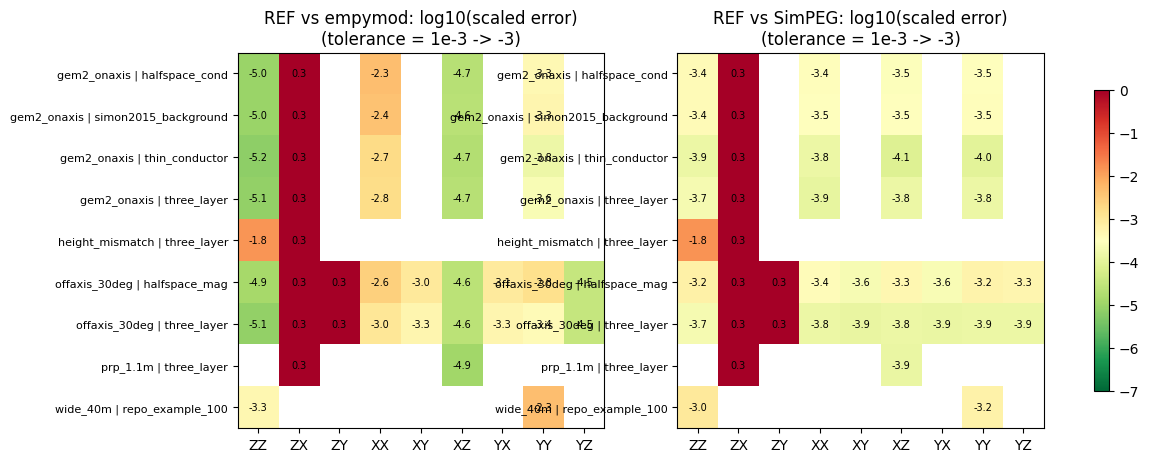

In [10]:
def plot_error_matrix(results, version):
    subset = results[(results.version == version) & results.scaled_error.notna()].copy()
    subset["case"] = subset.geometry + " | " + subset.earth
    references = subset.reference.unique()
    fig, axes = plt.subplots(1, len(references), figsize=(6.5 * len(references), 0.32 * subset.case.nunique() + 2),
                             squeeze=False)
    for ax, reference_name in zip(axes[0], references):
        matrix = (subset[subset.reference == reference_name]
                  .pivot_table(index="case", columns="ori", values="scaled_error", aggfunc="max")
                  .reindex(columns=[o for o in ALL_ORIENTATIONS if o in subset.ori.unique()]))
        image = ax.imshow(np.log10(matrix.values.astype(float)), cmap="RdYlGn_r", vmin=-7, vmax=0, aspect="auto")
        ax.set_xticks(range(matrix.shape[1]), matrix.columns)
        ax.set_yticks(range(matrix.shape[0]), matrix.index, fontsize=8)
        ax.set_title(f"{version} vs {reference_name}: log10(scaled error)\n(tolerance = 1e-3 -> -3)")
        for (i, j), value in np.ndenumerate(matrix.values):
            if np.isfinite(value):
                ax.text(j, i, f"{np.log10(value):.1f}", ha="center", va="center", fontsize=7)
    fig.colorbar(image, ax=axes[0].tolist(), shrink=0.8)
    plt.show()


for version in VERSIONS:
    plot_error_matrix(forward_results, version)

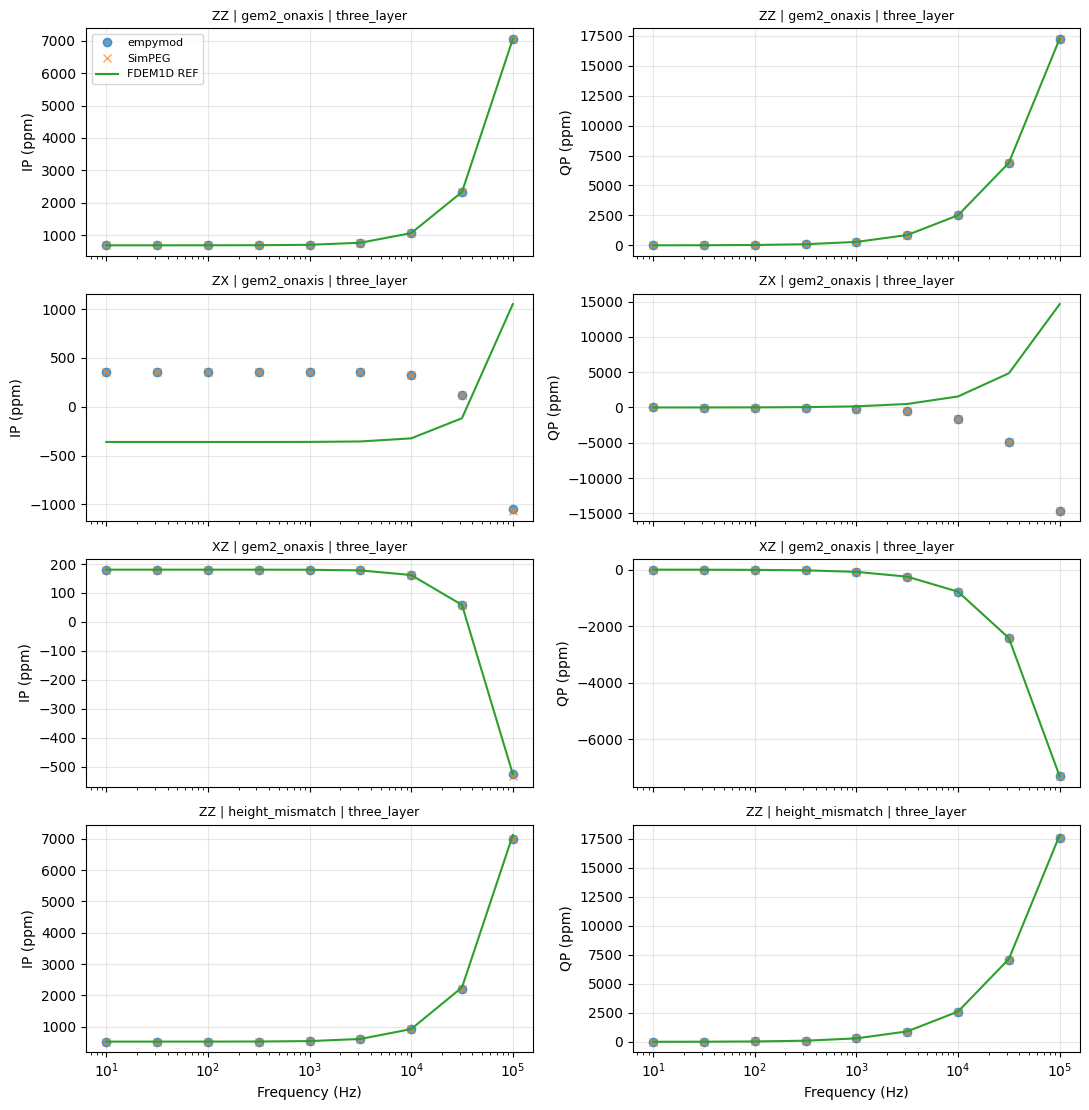

In [11]:
def plot_sweeps(results, cases, version="REF"):
    fig, axes = plt.subplots(len(cases), 2, figsize=(11, 2.8 * len(cases)), squeeze=False, sharex=True)
    for row, (geometry_name, earth_name, orientation) in enumerate(cases):
        for col, (part, label) in enumerate([(np.real, "IP (ppm)"), (np.imag, "QP (ppm)")]):
            ax = axes[row, col]
            selection = results[(results.geometry == geometry_name) & (results.earth == earth_name)
                                & (results.ori == orientation) & results.scaled_error.notna()]
            for _, r in selection[selection.version == version].iterrows():
                ax.semilogx(FREQUENCIES_HZ, part(r.ref_ppm), "o" if r.reference == "empymod" else "x",
                            label=r.reference, alpha=0.7)
            for v in VERSIONS:
                first = selection[selection.version == v].iloc[0]
                ax.semilogx(FREQUENCIES_HZ, part(first.fdem_ppm), "-" if v == "REF" else "--", label=f"FDEM1D {v}")
            ax.set_title(f"{orientation} | {geometry_name} | {earth_name}", fontsize=9)
            ax.set_ylabel(label)
            ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=8)
    for ax in axes[-1]:
        ax.set_xlabel("Frequency (Hz)")
    plt.tight_layout()
    plt.show()


plot_sweeps(forward_results, [("gem2_onaxis", "three_layer", "ZZ"),
                              ("gem2_onaxis", "three_layer", "ZX"),
                              ("gem2_onaxis", "three_layer", "XZ"),
                              ("height_mismatch", "three_layer", "ZZ")])

## 8. Invariant tests (no external code)

| Test | Exact property |
|---|---|
| reciprocity | H^S_AB(x, y) = H^S_BA(−x, −y) → H^S_ZX = −H^S_XZ, H^S_ZY = −H^S_YZ, H^S_XY = H^S_YX (raw fields) |
| RC = PM | both wave-propagation methods solve the same boundary-value problem |
| layer splitting | splitting a layer into identical sub-layers leaves the response unchanged |
| free space | σ = 0, κ = 0, ε = ε0 → zero secondary field |
| LIN asymptote | HCP at h = 0 over a half-space: QP → ωμ0σs²/4 (McNeill, 1980) for B = s/δ ≪ 1 |
| κ linearity | σ → 0, low f: IP ∝ κ for κ ≪ 1 |
| input contract | forward returns scalars; mismatched layer arrays are rejected |

In [12]:
def check(name, version, passed, detail, tolerance=None):
    return dict(test=name, version=version, status="PASS" if passed else "FAIL", detail=detail, tolerance=tolerance)


def run_invariant_tests(adapter, version):
    rows = []
    off_axis, on_axis = GEOMETRIES["offaxis_30deg"], GEOMETRIES["gem2_onaxis"]
    earth = EARTHS["three_layer"]
    frequency_hz = 5010.0

    def guarded(name, function):
        try:
            rows.extend(function())
        except Exception as exc:
            rows.append(dict(test=name, version=version, status="ERROR", detail=repr(exc)))

    def reciprocity():
        out = []
        for a, b, sign in [("ZX", "XZ", -1), ("ZY", "YZ", -1), ("XY", "YX", +1)]:
            h_ab = adapter.raw_secondary(off_axis, earth, frequency_hz, a)
            h_ba = adapter.raw_secondary(off_axis, earth, frequency_hz, b)
            residual = abs(h_ab - sign * h_ba) / abs(h_ab)
            out.append(check(f"reciprocity {a} = {'+' if sign > 0 else '-'}{b}", version, residual < 1e-6,
                             f"relative residual {residual:.1e}", 1e-6))
        return out

    def rc_equals_pm():
        if "PM" not in adapter.methods:
            return []
        rc = adapter.ppm(on_axis, earth, FREQUENCIES_HZ, "ZZ", method="RC")
        pm = adapter.ppm(on_axis, earth, FREQUENCIES_HZ, "ZZ", method="PM")
        difference = np.max(np.abs(rc - pm)) / np.max(np.abs(rc))
        return [check("RC = PM (ZZ, 3-layer)", version, difference < 1e-9, f"scaled diff {difference:.1e}", 1e-9)]

    def layer_splitting():
        whole = EARTHS["halfspace_mag"]
        split = LayeredEarth("split", (0.4, 0.7), whole.conductivity_s_per_m * 3, whole.susceptibility_si * 3,
                             whole.rel_permittivity * 3)
        a = adapter.ppm(on_axis, whole, FREQUENCIES_HZ, "ZZ")
        b = adapter.ppm(on_axis, split, FREQUENCIES_HZ, "ZZ")
        difference = np.max(np.abs(a - b)) / np.max(np.abs(a))
        return [check("layer splitting (3 identical layers = half-space)", version, difference < 1e-9,
                      f"scaled diff {difference:.1e}", 1e-9)]

    def free_space():
        vacuum = LayeredEarth("vacuum", (), (0.0,), (0.0,), (1.0,))
        response = adapter.ppm(on_axis, vacuum, FREQUENCIES_HZ, "ZZ")
        return [check("free space -> 0 ppm", version, np.max(np.abs(response)) < 1e-6,
                      f"max |ppm| {np.max(np.abs(response)):.1e}", 1e-6)]

    def lin_asymptote():
        geometry = Geometry("hcp_ground", offset_m=1.0, tx_height_m=1e-6)
        conductivity, frequency = 0.01, 100.0
        response = adapter.ppm(geometry, LayeredEarth("hs", (), (conductivity,), (0.0,), (1.0,)), frequency, "ZZ")[0]
        expected_qp = 1e6 * 2 * np.pi * frequency * mu_0 * conductivity * geometry.offset_m**2 / 4
        induction_number = geometry.offset_m / np.sqrt(2 / (2 * np.pi * frequency * mu_0 * conductivity))
        tolerance = max(5 * induction_number, 1e-3)      # next-order LIN term is O(B)
        difference = abs(response.imag - expected_qp) / expected_qp
        return [check("LIN asymptote QP = w mu0 sigma s^2 / 4", version, difference < tolerance,
                      f"rel diff {difference:.1e} (B = {induction_number:.1e})", tolerance)]

    def susceptibility_linearity():
        responses = [adapter.ppm(on_axis, LayeredEarth("k", (), (1e-6,), (k,), (1.0,)), 100.0, "ZZ")[0].real
                     for k in (1e-4, 2e-4)]
        ratio = responses[1] / responses[0]
        return [check("IP linear in kappa (sigma -> 0)", version, abs(ratio - 2) < 1e-3,
                      f"IP(2k)/IP(k) = {ratio:.5f}", 1e-3)]

    def input_contract():
        out = []
        if isinstance(adapter, LegacyFDEM1DAdapter):
            sensor, model = adapter._build(on_axis, earth, frequency_hz, "ZZ")
            ip, _ = adapter.module.Calculate(sensor, model).forward()
            out.append(check("forward returns scalars", version, np.ndim(ip) == 0, f"type {type(ip).__name__}, "
                             f"shape {np.shape(ip)}"))
            try:   # 2 conductivities but a single thickness entry -> must be rejected, not silently truncated
                bad = adapter.module.Model(np.array([0.5]), np.array([0.0, 0.0]), np.array([0.01, 0.5]),
                                           np.array([0.0, 0.0]))
                adapter.module.Calculate(sensor, bad).forward()
                out.append(check("mismatched layer arrays rejected", version, False, "accepted silently"))
            except Exception as exc:
                out.append(check("mismatched layer arrays rejected", version, True, type(exc).__name__))
        return out

    for name, function in [("reciprocity", reciprocity), ("RC = PM", rc_equals_pm), ("layer splitting", layer_splitting),
                           ("free space", free_space), ("LIN asymptote", lin_asymptote),
                           ("kappa linearity", susceptibility_linearity), ("input contract", input_contract)]:
        guarded(name, function)
    return rows


invariant_results = pd.DataFrame([row for version, adapter in VERSIONS.items()
                                  for row in run_invariant_tests(adapter, version)])
print(invariant_results.to_string(index=False))

                                             test version status                         detail  tolerance
                             reciprocity ZX = -XZ     REF   FAIL      relative residual 2.0e+00  1.000e-06
                             reciprocity ZY = -YZ     REF   FAIL      relative residual 2.0e+00  1.000e-06
                             reciprocity XY = +YX     REF   PASS      relative residual 0.0e+00  1.000e-06
                            RC = PM (ZZ, 3-layer)     REF   PASS            scaled diff 2.8e-14  1.000e-09
layer splitting (3 identical layers = half-space)     REF   PASS            scaled diff 7.3e-14  1.000e-09
                              free space -> 0 ppm     REF   PASS              max |ppm| 0.0e+00  1.000e-06
           LIN asymptote QP = w mu0 sigma s^2 / 4     REF   PASS rel diff 2.1e-03 (B = 2.0e-03)  9.935e-03
                  IP linear in kappa (sigma -> 0)     REF   PASS         IP(2k)/IP(k) = 1.99990  1.000e-03
                          forward ret

## 9. Sensitivity tests

References for d(ppm)/d(m_n), per layer n (HCP, 5010 Hz, three-layer model):

1. **Independent central difference** built only from `ppm()` calls, with a per-layer step
   Δ_n = 1e-4·|m_n| (absolute 1e-6 if m_n = 0) — catches step-bookkeeping errors in `sensitivity()`.
2. **SimPEG analytic Jacobian** (quasi-static; FDEM1D run with ground ε = 0).

Tolerance 2e-2 (scaled by max_n |J_n|): FDEM1D's legacy routine uses a 1 % one-sided step, whose truncation
error is O(Δ/2 · H''/H') ~ 1e-2. A refactored central-difference or analytic implementation should pass at
much tighter tolerance — tighten `RTOL_SENS_*` for NEW once implemented.

Also checked: zero-valued parameters give finite sensitivities, and the model object is not mutated.

In [13]:
def central_difference_ppm(adapter, geometry, earth, frequency_hz, orientation, par, quasi_static=False,
                           relative_step=1e-4, absolute_step=1e-6):
    values = np.asarray(getattr(earth, {"con": "conductivity_s_per_m", "sus": "susceptibility_si"}[par]), float)
    jacobian = np.zeros(earth.n_layers, complex)
    for n in range(earth.n_layers):
        step = relative_step * abs(values[n]) if values[n] != 0 else absolute_step
        plus, minus = values.copy(), values.copy()
        plus[n] += step
        minus[n] -= step
        if par == "con":
            minus[n] = max(minus[n], 0.0)
        f_plus = adapter.ppm(geometry, earth.with_property(par, plus), frequency_hz, orientation, quasi_static)[0]
        f_minus = adapter.ppm(geometry, earth.with_property(par, minus), frequency_hz, orientation, quasi_static)[0]
        jacobian[n] = (f_plus - f_minus) / (plus[n] - minus[n])
    return jacobian


def run_sensitivity_tests(adapter, version):
    rows = []
    geometry, frequency_hz, orientation = GEOMETRIES["gem2_onaxis"], 5010.0, "ZZ"
    base = EARTHS["three_layer"]
    cases = [("con", base, "three_layer"),
             ("sus", base, "three_layer"),
             ("sus", base.with_property("sus", (2e-3, 0.0, 0.0)), "three_layer, kappa = 0 below layer 1")]
    for par, earth, label in cases:
        try:
            sens, mutated = adapter.sensitivity(geometry, earth, frequency_hz, orientation, par)
        except Exception as exc:
            rows.append(dict(test=f"sensitivity {par} ({label})", version=version, status="ERROR", detail=repr(exc)))
            continue
        rows.append(check(f"model not mutated ({par})", version, not mutated, "mutated" if mutated else "unchanged"))
        finite = np.all(np.isfinite(sens))
        rows.append(check(f"finite sensitivity {par} ({label})", version, finite, np.array2string(sens, precision=1)))
        if not finite:
            continue
        reference = central_difference_ppm(adapter, geometry, earth, frequency_hz, orientation, par)
        error = np.max(np.abs(sens - reference)) / np.max(np.abs(reference))
        rows.append(check(f"vs central difference: {par} ({label})", version, error < RTOL_SENS_FD,
                          f"scaled error {error:.1e}; per-layer ratio "
                          f"{np.array2string(np.abs(sens / reference), precision=2)}", RTOL_SENS_FD))
        if RUN_SIMPEG:
            sens_qs, _ = adapter.sensitivity(geometry, earth, frequency_hz, orientation, par, quasi_static=True)
            reference_qs = simpeg_jacobian_ppm(geometry, earth, frequency_hz, orientation, par)
            error = np.max(np.abs(sens_qs - reference_qs)) / np.max(np.abs(reference_qs))
            rows.append(check(f"vs SimPEG analytic J: {par} ({label})", version, error < RTOL_SENS_SIMPEG,
                              f"scaled error {error:.1e}", RTOL_SENS_SIMPEG))
    return rows


sensitivity_results = pd.DataFrame([row for version, adapter in VERSIONS.items()
                                    for row in run_sensitivity_tests(adapter, version)])
print(sensitivity_results.to_string(index=False))

                                                         test version status                                                  detail  tolerance
                                      model not mutated (con)     REF   PASS                                               unchanged        NaN
                         finite sensitivity con (three_layer)     REF   PASS          [  71.7+2975.7j   27.1 +809.5j 1931.9+8598.6j]        NaN
                     vs central difference: con (three_layer)     REF   FAIL     scaled error 8.3e-01; per-layer ratio [0.5 0.1 1. ]       0.02
                      vs SimPEG analytic J: con (three_layer)     REF   FAIL                                    scaled error 8.3e-01       0.02
                                      model not mutated (sus)     REF   PASS                                               unchanged        NaN
                         finite sensitivity sus (three_layer)     REF   PASS [7080597.2  +65.9j -144400.4 +958.4j  -53923.3+1066.7j]    

### Reference-only sanity check: FDEM1D-independent sensitivity profile

Independent central difference on FDEM1D forward vs SimPEG's analytic Jacobian — validates the reference
machinery itself, so a sensitivity failure above can be attributed to `sensitivity()` and not to the test.

In [14]:
if RUN_SIMPEG:
    geometry, earth = GEOMETRIES["gem2_onaxis"], EARTHS["three_layer"]
    for par in ("con", "sus"):
        fd_reference = central_difference_ppm(VERSIONS["REF"], geometry, earth, 5010.0, "ZZ", par, quasi_static=True)
        analytic = simpeg_jacobian_ppm(geometry, earth, 5010.0, "ZZ", par)
        print(f"{par}: |FD(FDEM1D forward) - SimPEG J| / max|J| = "
              f"{np.max(np.abs(fd_reference - analytic)) / np.max(np.abs(analytic)):.1e}")

con: |FD(FDEM1D forward) - SimPEG J| / max|J| = 5.9e-06
sus: |FD(FDEM1D forward) - SimPEG J| / max|J| = 6.0e-06


## 10. Performance

Best-of-N wall time on this machine (single frequency unless stated; HCP, 1.66 m, 0.3 m height). Timings
include each code's Python overhead (object construction), which is what a user experiences per call.

In [15]:
def best_time(function, repeats=5):
    best = np.inf
    for _ in range(repeats):
        t0 = time.perf_counter()
        function()
        best = min(best, time.perf_counter() - t0)
    return best


def uniform_earth(n_layers):
    return LayeredEarth(f"uniform_{n_layers}", tuple(np.full(n_layers - 1, 0.1)), (0.02,) * n_layers,
                        (1e-3,) * n_layers, (1.0,) * n_layers)


timing_rows = []
if RUN_TIMING:
    geometry = GEOMETRIES["gem2_onaxis"]
    for n_layers in ([1, 10, 100] if FAST else [1, 10, 50, 100]):
        earth = uniform_earth(n_layers)
        for version, adapter in VERSIONS.items():
            for method in adapter.methods:
                timing_rows.append(dict(code=f"FDEM1D {version} {method}", task="forward, 1 f", n_layers=n_layers,
                                        seconds=best_time(lambda: adapter.ppm(geometry, earth, 5010.0, "ZZ",
                                                                              method=method))))
            timing_rows.append(dict(code=f"FDEM1D {version} RC", task="forward, 9 f", n_layers=n_layers,
                                    seconds=best_time(lambda: adapter.ppm(geometry, earth, FREQUENCIES_HZ, "ZZ"))))
            try:
                seconds = best_time(lambda: adapter.sensitivity(geometry, earth, 5010.0, "ZZ", "con"), repeats=1)
            except Exception:
                seconds = np.nan
            timing_rows.append(dict(code=f"FDEM1D {version} RC", task="sensitivity (con), 1 f", n_layers=n_layers,
                                    seconds=seconds))
        timing_rows.append(dict(code="empymod qwe", task="forward, 1 f", n_layers=n_layers,
                                seconds=best_time(lambda: empymod_ppm(geometry, earth, [5010.0], "ZZ"))))
        timing_rows.append(dict(code="empymod qwe", task="forward, 9 f", n_layers=n_layers,
                                seconds=best_time(lambda: empymod_ppm(geometry, earth, FREQUENCIES_HZ, "ZZ"))))
        if RUN_SIMPEG:
            timing_rows.append(dict(code="SimPEG", task="forward, 1 f", n_layers=n_layers,
                                    seconds=best_time(lambda: simpeg_ppm(geometry, earth, [5010.0], "ZZ"))))
            timing_rows.append(dict(code="SimPEG", task="forward, 9 f", n_layers=n_layers,
                                    seconds=best_time(lambda: simpeg_ppm(geometry, earth, FREQUENCIES_HZ, "ZZ"))))
            timing_rows.append(dict(code="SimPEG", task="sensitivity (con), 1 f", n_layers=n_layers,
                                    seconds=best_time(lambda: simpeg_jacobian_ppm(geometry, earth, 5010.0, "ZZ",
                                                                                  "con"), repeats=1)))
timing_results = pd.DataFrame(timing_rows)
if RUN_TIMING:
    table = timing_results.pivot_table(index=["task", "code"], columns="n_layers", values="seconds") * 1e3
    print("wall time (ms)\n", table.round(2).to_string())

wall time (ms)
 n_layers                                1      10     50      100
task                   code                                      
forward, 1 f           FDEM1D REF PM   0.20   2.88  14.97   29.95
                       FDEM1D REF RC   0.15   0.31   1.02    1.75
                       SimPEG          0.88   0.97   1.40    2.04
                       empymod qwe     5.50   5.91   8.13   11.55
forward, 9 f           FDEM1D REF RC   1.33   2.68   8.87   16.11
                       SimPEG          2.72   3.49   7.23   11.81
                       empymod qwe    43.00  47.84  68.47   98.83
sensitivity (con), 1 f FDEM1D REF RC   0.47   5.74  97.37  391.51
                       SimPEG          1.30   1.46   2.74    4.12


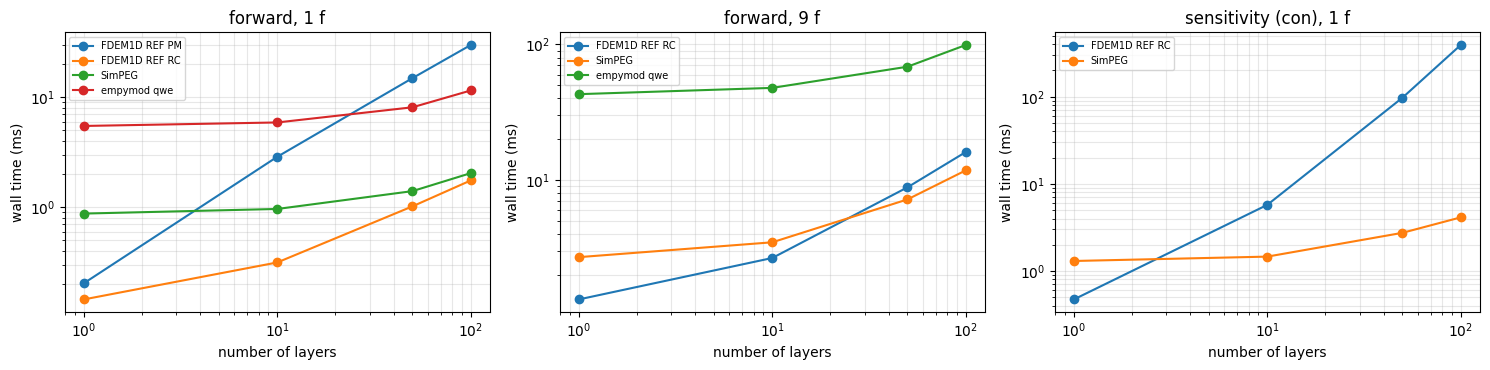

In [16]:
if RUN_TIMING:
    tasks = timing_results.task.unique()
    fig, axes = plt.subplots(1, len(tasks), figsize=(5 * len(tasks), 3.8), squeeze=False)
    for ax, task in zip(axes[0], tasks):
        for code, group in timing_results[timing_results.task == task].groupby("code"):
            ax.loglog(group.n_layers, group.seconds * 1e3, "o-", label=code)
        ax.set(title=task, xlabel="number of layers", ylabel="wall time (ms)")
        ax.grid(alpha=0.3, which="both")
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

## 11. Current (REF) vs refactored (NEW)

Expected differences (documented fixes); everything else must agree to `RTOL_VERSION`:

- ZX, ZY: NEW = −REF (erratum to eq. 7–8), unless NEW is run with a legacy output convention.
- Tx/Rx height mismatch: NEW corrects the Bessel argument.

In [17]:
EXPECTED_VERSION_CHANGES = [
    (lambda g, e, o: o in ("ZX", "ZY") and GEOMETRIES[g].rx_height == GEOMETRIES[g].tx_height_m, "negated"),
    (lambda g, e, o: GEOMETRIES[g].rx_height != GEOMETRIES[g].tx_height_m, "changed"),
]

if "NEW" in VERSIONS:
    rows = []
    empymod_rows = forward_results[forward_results.reference == "empymod"]
    for (geometry_name, earth_name, orientation), group in empymod_rows.groupby(["geometry", "earth", "ori"]):
        ref_row, new_row = (group[group.version == v] for v in ("REF", "NEW"))
        if ref_row.empty or new_row.empty or ref_row.scaled_error.isna().any() or new_row.scaled_error.isna().any():
            rows.append(dict(geometry=geometry_name, earth=earth_name, ori=orientation, status="ERROR"))
            continue
        ref_ppm, new_ppm = ref_row.iloc[0].fdem_ppm, new_row.iloc[0].fdem_ppm
        scale = np.max(np.abs(ref_ppm))
        same = np.max(np.abs(new_ppm - ref_ppm)) / scale
        negated = np.max(np.abs(new_ppm + ref_ppm)) / scale
        expected = next((kind for match, kind in EXPECTED_VERSION_CHANGES
                         if match(geometry_name, earth_name, orientation)), "identical")
        observed = "identical" if same < RTOL_VERSION else ("negated" if negated < RTOL_VERSION else "changed")
        rows.append(dict(geometry=geometry_name, earth=earth_name, ori=orientation, expected=expected,
                         observed=observed, diff_same=same, diff_negated=negated,
                         status="PASS" if observed == expected else "FAIL"))
    version_comparison = pd.DataFrame(rows)
    print(version_comparison.groupby(["expected", "observed", "status"]).size().to_string())
    unexpected = version_comparison[version_comparison.status != "PASS"]
    print("\nUnexpected REF -> NEW changes:\n", unexpected.to_string(index=False) if len(unexpected) else "  none")
else:
    version_comparison = pd.DataFrame()
    print("NEW version not loaded - skipped.")

NEW version not loaded - skipped.


## 12. Summary

In [18]:
summary_rows = []
for version in VERSIONS:
    forward_v = forward_results[forward_results.version == version]
    for reference_name, group in forward_v.groupby("reference"):
        counts = group.status.value_counts()
        summary_rows.append(dict(version=version, suite=f"forward vs {reference_name}", **counts.to_dict()))
    for suite_name, table in [("invariants", invariant_results), ("sensitivity", sensitivity_results)]:
        counts = table[table.version == version].status.value_counts()
        summary_rows.append(dict(version=version, suite=suite_name, **counts.to_dict()))
if len(version_comparison):
    summary_rows.append(dict(version="REF->NEW", suite="version comparison",
                             **version_comparison.status.value_counts().to_dict()))
summary = pd.DataFrame(summary_rows).fillna(0)
for column in ("PASS", "KNOWN", "FAIL", "ERROR"):
    if column not in summary:
        summary[column] = 0
summary = summary[["version", "suite", "PASS", "KNOWN", "FAIL", "ERROR"]].astype(
    {c: int for c in ("PASS", "KNOWN", "FAIL", "ERROR")})
print(summary.to_string(index=False))
print("\nKNOWN = failure explained by a documented defect of that version (see KNOWN_ISSUES in section 6).")

if SAVE_RESULTS:
    forward_results.drop(columns=["fdem_ppm", "ref_ppm"]).to_csv("fdem1d_forward_benchmarks.csv", index=False)
    invariant_results.to_csv("fdem1d_invariant_tests.csv", index=False)
    sensitivity_results.to_csv("fdem1d_sensitivity_tests.csv", index=False)
    timing_results.to_csv("fdem1d_timings.csv", index=False)
    print("CSV files written.")

version              suite  PASS  KNOWN  FAIL  ERROR
    REF  forward vs SimPEG    33     11     0      0
    REF forward vs empymod    25     19     0      0
    REF         invariants     6      0     4      0
    REF        sensitivity     5      0     5      0

KNOWN = failure explained by a documented defect of that version (see KNOWN_ISSUES in section 6).
